First five rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies    

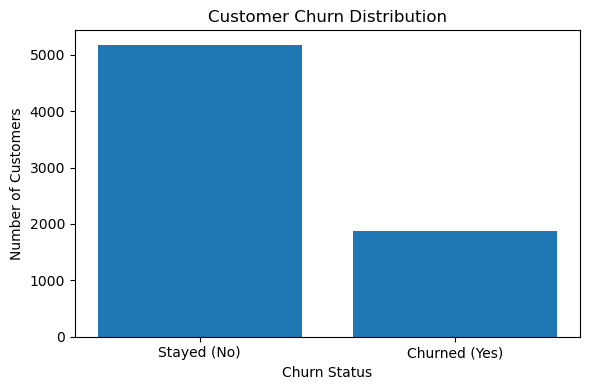


Churn rate by contract type (%):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Missing values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Training samples: 5634
Testing samples: 1409

Model Performance:
Accuracy: 0.7984
Precision: 0.6347
Recall: 0.5668
F1 Score: 0.5989

Confusion Matrix:
[[913 122]
 [162 212]]

Actual vs Predicted:
    Actual Predicted
0   Stayed    Stayed
1   Stayed   Churned
2   Stayed    Stayed
3   Stayed   Churned
4   Stayed    Stayed
5   Stayed    Stayed


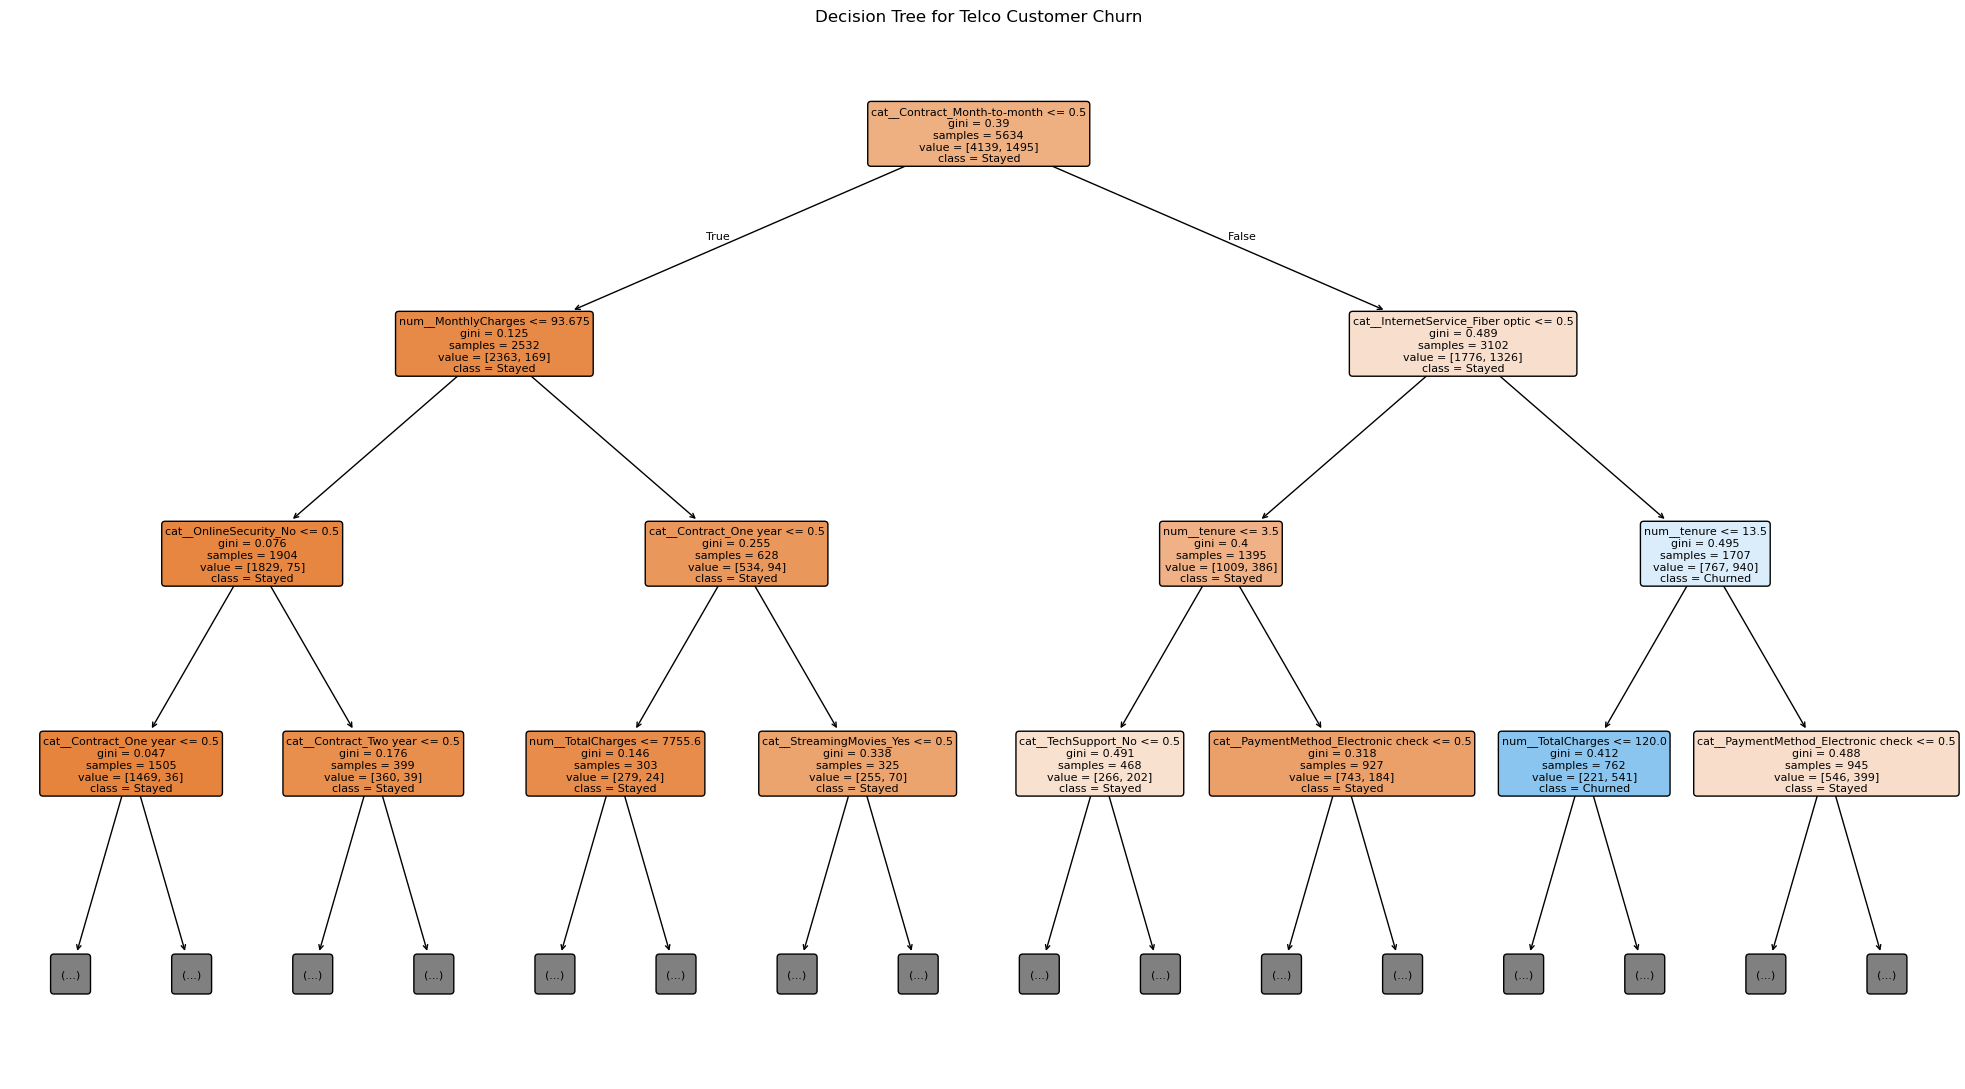

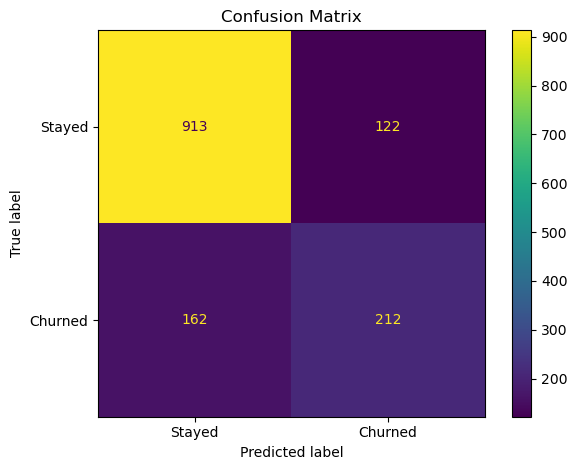


Top 8 Feature Importances:
cat__Contract_Month-to-month           0.517673
cat__InternetService_Fiber optic       0.164438
num__tenure                            0.154620
num__MonthlyCharges                    0.038483
num__TotalCharges                      0.033084
cat__PaymentMethod_Electronic check    0.028132
cat__TechSupport_No                    0.021531
cat__Contract_One year                 0.009285
dtype: float64


In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

# 1. Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

# 2. Exploratory Data Analysis
print("\nClass distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

# Visualize class distribution
counts = df["Churn"].value_counts().reindex(["No", "Yes"])

plt.figure(figsize=(6, 4))
plt.bar(["Stayed (No)", "Churned (Yes)"], counts.values)
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.title("Customer Churn Distribution")
plt.tight_layout()
plt.show()

# Check churn rate by contract type
print("\nChurn rate by contract type (%):")
print(
    (
        df.groupby("Contract")["Churn"]
        .apply(lambda s: (s == "Yes").mean()) * 100
    ).round(2)
)

# 3. Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("\nMissing values:")
print(df.isnull().sum())

# 4. Separate features and target
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# 5. Identify numeric and categorical columns
numeric_cols = X.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X.select_dtypes(
    exclude="number"
).columns.tolist()

# 6. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 7. Preprocess numerical and categorical features
num_transformer = SimpleImputer(strategy="median")

cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_transformer, numeric_cols),
    ("cat", cat_transformer, categorical_cols)
])

# 8. Create the Decision Tree model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ))
])

# 9. Train the model
model.fit(X_train, y_train)

# 10. Predict customer churn
y_pred = model.predict(X_test)

# 11. Evaluate performance
print("\nModel Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred):.4f}")

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(cm)

# 12. Actual vs Predicted
results = pd.DataFrame({
    "Actual": y_test.map({
        0: "Stayed", 1: "Churned"
    }).values,
    "Predicted": pd.Series(y_pred).map({
        0: "Stayed", 1: "Churned"
    }).values
})

print("\nActual vs Predicted:")
print(results.head(10))

# 13. Visualize Decision Tree
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

tree = model.named_steps["classifier"]

plt.figure(figsize=(20, 11))

plot_tree(
    tree,
    feature_names=feature_names,
    class_names=["Stayed", "Churned"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree for Telco Customer Churn")
plt.tight_layout()
plt.show()

# 14. Visualize Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# 15. Display most important features
importance = pd.Series(
    tree.feature_importances_,
    index=feature_names
)

print("\nTop 8 Feature Importances:")
print(importance.nlargest(8))
